## 运行说明

本 notebook 是该分析的用户入口：先检查并生成所需 `logs/`，再读取结果、完成分析并把图片写入同名 `figures/` 目录。

- 默认 `FORCE_RECOMPUTE = False`：已有日志直接复用，缺失日志才计算。
- 若需要从数据重新计算本 notebook 依赖的日志，将下一单元中的开关改为 `True`。
- 耗时较长的计算保留在同目录、同主题的 `.py` 中；短计算直接写在本 notebook 中。


In [1]:
from pathlib import Path
import subprocess

PROJECT_ROOT = Path('..').resolve()
SCRIPT_DIR = PROJECT_ROOT / 'scripts'
PYTHON = PROJECT_ROOT / 'venv/bin/python'
FORCE_RECOMPUTE = False

def run_long_task(script_name, sentinel, *arguments):
    sentinel = PROJECT_ROOT / sentinel
    if FORCE_RECOMPUTE or not sentinel.exists():
        command = [str(PYTHON), str(SCRIPT_DIR / script_name), *map(str, arguments)]
        print('运行：', ' '.join(command))
        subprocess.run(command, cwd=PROJECT_ROOT, check=True)
    else:
        print('复用：', sentinel.relative_to(PROJECT_ROOT))

run_long_task('261027空间事件传播.py', 'logs/spatial_bin_event_propagation/initial/summary.csv')
run_long_task('261027空间事件传播.py', 'logs/spatial_bin_event_propagation/seed_20261010/summary.csv', '--seed', '20261010', '--output-dir', 'logs/spatial_bin_event_propagation/seed_20261010')
run_long_task('261027空间事件传播.py', 'logs/spatial_bin_event_propagation/seed_20261011/summary.csv', '--seed', '20261011', '--output-dir', 'logs/spatial_bin_event_propagation/seed_20261011')
run_long_task('261027脑状态转换空间动力学.py', 'logs/spatial_state_transitions/initial/summary.csv')
run_long_task('261027脑状态转换空间动力学.py', 'logs/spatial_state_transitions/seed_20261010/summary.csv', '--event-arrays', 'logs/spatial_bin_event_propagation/seed_20261010/event_arrays.npz', '--output-dir', 'logs/spatial_state_transitions/seed_20261010')
run_long_task('261027脑状态转换空间动力学.py', 'logs/spatial_state_transitions/seed_20261011/summary.csv', '--event-arrays', 'logs/spatial_bin_event_propagation/seed_20261011/event_arrays.npz', '--output-dir', 'logs/spatial_state_transitions/seed_20261011')


复用： logs/spatial_bin_event_propagation/initial/summary.csv
复用： logs/spatial_bin_event_propagation/seed_20261010/summary.csv
复用： logs/spatial_bin_event_propagation/seed_20261011/summary.csv
复用： logs/spatial_state_transitions/initial/summary.csv
复用： logs/spatial_state_transitions/seed_20261010/summary.csv
复用： logs/spatial_state_transitions/seed_20261011/summary.csv


# EEG-defined state-transition dynamics

Awake↔NREM boundaries provide an external time arrow. Spatial-bin trajectories are normalized between pre/post baselines, smoothed, monotonized by isotonic regression, and assigned a 50% transition time.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression
from yumeow_plot import get_fig
ROOT = Path('..').resolve()
RUNS = ROOT / 'logs/spatial_state_transitions'
OUT = ROOT / 'figures/261027脑状态转换空间动力学'
OUT.mkdir(parents=True, exist_ok=True)
archive = np.load(RUNS / 'initial/transition_arrays.npz')
offsets = archive['offsets_seconds']
run_names = ['initial', 'seed_20261010', 'seed_20261011']
summary = pd.concat([pd.read_csv(RUNS / run / 'summary.csv').assign(run=run) for run in run_names], ignore_index=True)
summary

,transition,n_events,plane_r2,plane_permutation_p,gradient_seconds_per_spatial_sd,angle_degrees,bootstrap_angle_resultant,bootstrap_plane_r2_median,run
0,Awake_to_NREM,46,0.268852,0.004995,4.483698,-154.310397,0.975611,0.285941,initial
1,NREM_to_Awake,41,0.105847,0.156843,2.109875,-165.400095,0.969711,0.167113,initial
2,Awake_to_NREM,46,0.261045,0.007992,4.159535,-131.329437,0.970831,0.202519,seed_20261010
3,NREM_to_Awake,41,0.278334,0.004995,3.790593,-177.020289,0.970802,0.225554,seed_20261010
4,Awake_to_NREM,46,0.312328,0.002997,4.618885,-136.986654,0.978764,0.292809,seed_20261011
5,NREM_to_Awake,41,0.297469,0.003996,3.626790,-172.871231,0.967873,0.256707,seed_20261011


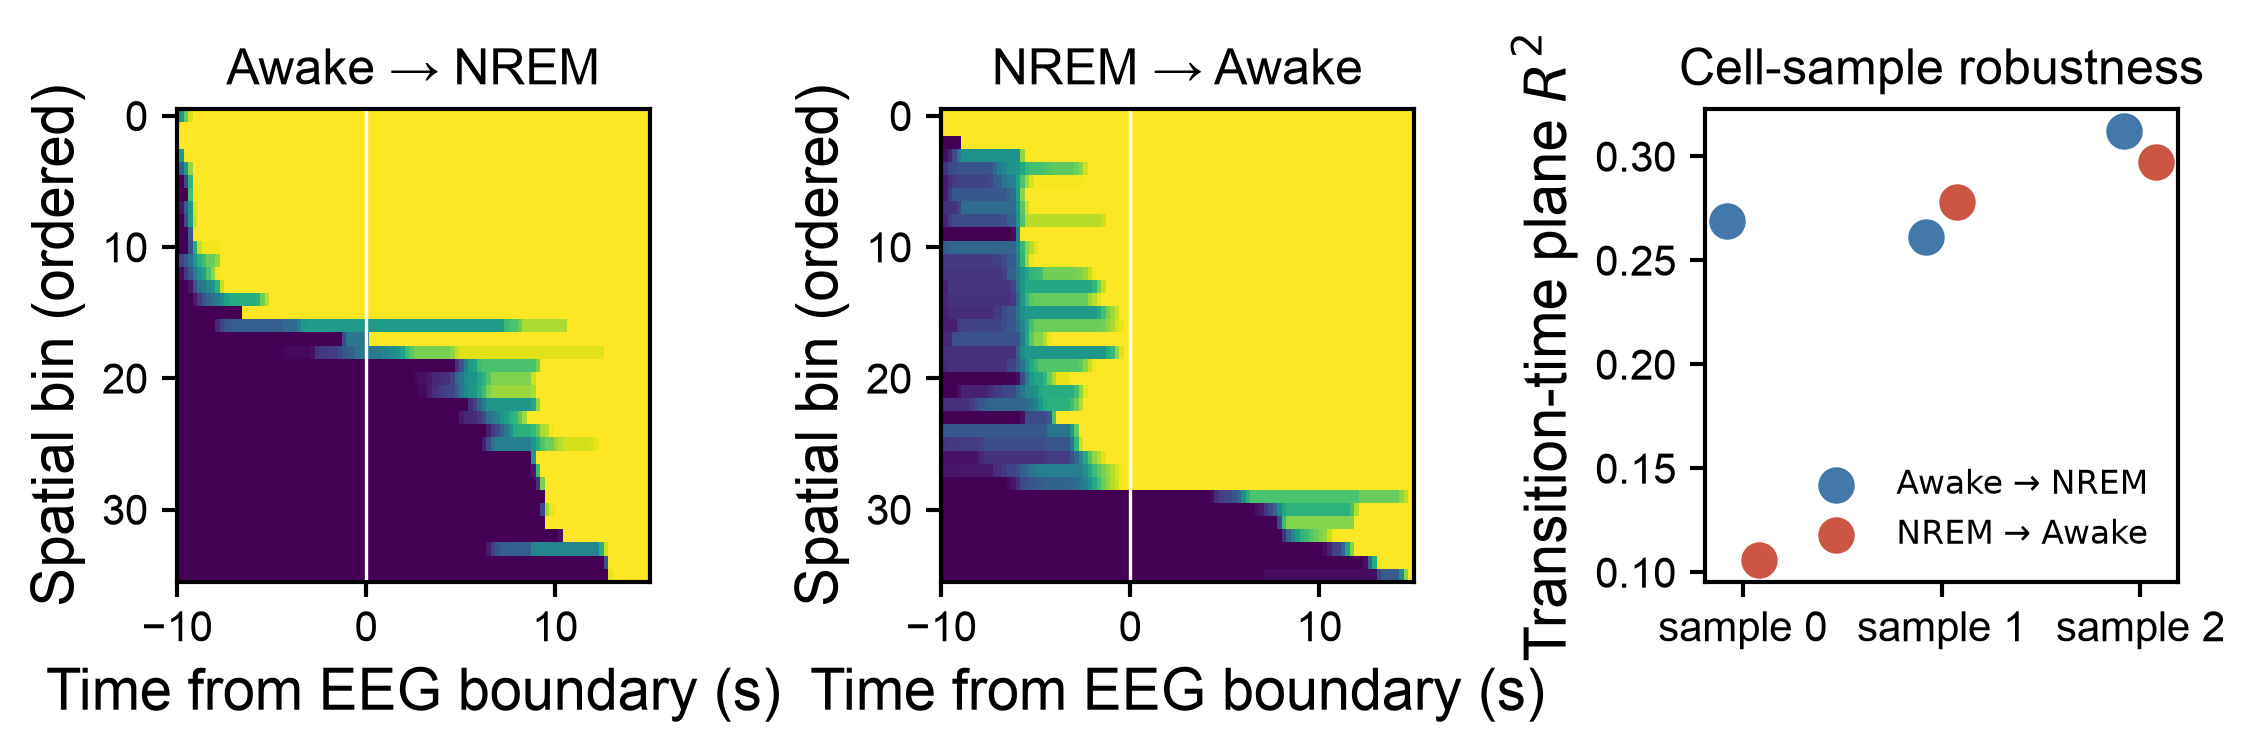

In [3]:
transitions = ['Awake_to_NREM', 'NREM_to_Awake']
titles = ['Awake → NREM', 'NREM → Awake']
colors = {'Awake_to_NREM': '#4477aa', 'NREM_to_Awake': '#cc5544'}
fig, axes = get_fig(RN=1, CN=3, AW=4, AH=4, LM=5, RM=5, TM=5, BM=5, VS=5, HS=5, fontsize=14, dpi=300, lw=1)
ax_loader = iter(axes)
for transition, title in zip(transitions, titles):
    ax = next(ax_loader)
    progress = archive[f'{transition}_progress']
    lags = archive[f'{transition}_lags']
    order = np.argsort(lags)
    mask = (offsets >= -10) & (offsets <= 15)
    monotonic = np.stack([IsotonicRegression().fit_transform(offsets[mask], progress[mask, index]) for index in range(progress.shape[1])])
    ax.imshow(monotonic[order], aspect='auto', cmap='viridis', vmin=0, vmax=1, extent=[offsets[mask][0], offsets[mask][-1], len(lags)-.5, -.5])
    ax.axvline(0, color='white', lw=.8)
    ax.set(xlim=(-10, 15), xlabel='Time from EEG boundary (s)', ylabel='Spatial bin (ordered)', title=title)
ax = next(ax_loader)
for offset, transition in [(-.08, transitions[0]), (.08, transitions[1])]:
    part = summary[summary.transition == transition].set_index('run').loc[run_names]
    label = 'Awake → NREM' if transition == transitions[0] else 'NREM → Awake'
    ax.scatter(np.arange(3) + offset, part.plane_r2, s=60, color=colors[transition], label=label)
ax.set_xticks(range(3), ['sample 0', 'sample 1', 'sample 2'])
ax.set(ylabel='Transition-time plane $R^2$', title='Cell-sample robustness')
ax.legend(frameon=False, fontsize=8)
fig.savefig(OUT / 'spatial_state_transitions.png', transparent=True)
fig.savefig(OUT / 'spatial_state_transitions.svg', transparent=True)
fig.savefig(OUT / 'spatial_state_transitions.pdf', transparent=True)
plt.show()

Awake→NREM transition-time planes are significant in all three cell samples (R² 0.261–0.312, permutation p 0.003–0.008), but individual-bin bootstrap intervals are broad. NREM→Awake is significant in two samples and weaker in one (R² 0.106–0.297); its bin-level timing intervals are substantially narrower.

The two transition directions do not trace opposite spatial paths: both progress along a similar projected axis. NREM→Awake is currently the strongest candidate for externally anchored directional dynamics, whereas Awake→NREM should be treated as a slower, less precisely localized transition.